# 04 — The GAAP loss, and what an IPO buyer is really diluted by

**Question:** the S-1 shows a $104B net loss for nine months. What is it, why doesn't it matter for the business, and what *does* it tell an IPO buyer, namely how many shares exist and how many more are coming?

**Short answer**
1. Every year in the filing, most of the GAAP net loss is valuation marks, not operations. In 9M-2026 the marks were 101% of the loss. A business lost $1.3B at the operating line, and interest income more than covered it (§1, `04_net_loss_history.png`).
2. The marks are a *transfer between shareholders*, not a cost of running the company: Amazon's notes and Google/Amazon's share commitments got more valuable as Anthropic did. They stop at the IPO. Their real cost is the extra shares, which is what this notebook counts.
3. The headline −$50 loss per share divides by 2.1B weighted-average common shares. About **16.4B** shares exist or are already promised once preferred stock, Amazon's notes, the Public Benefit Fund, options and RSUs are counted, roughly 8x as many. Use the 16.4B for any per-share number (§2, `04_share_count.png`).
4. On top of that, new shares keep coming after the IPO: new employee grants, share-paid donations, the Public Benefit Fund's top-ups (up to 2% each time the stock rises 50%), and, in the bear case, equity to fund the compute bill. Through 2030 that's roughly **+6% (bear), +8% (base) and +14% (bull)** more shares. Most of it is the Public Benefit top-ups, so dilution is *highest* when the stock does best (§3, `04_future_dilution.png`).
5. Separately, $82B of partner facilities (Google, Amazon, Broadcom, AMD) can be settled in shares at market price. If fully drawn, that's another ~7% of today's count at the Sep-30 mark, but it brings in cash for compute (§3).
6. None of this changes revenue, margins or cash generation, except that public-benefit shares and donations are a deliberate, ongoing transfer of value away from shareholders. It changes *your slice*, not the pie (§4).

| § | Question | Chart |
|---|---|---|
| 1 | Has the GAAP loss always been mostly marks? | `04_net_loss_history.png` |
| 2 | How many shares really exist? | `04_share_count.png` |
| 3 | How many new shares could come after the IPO? | `04_future_dilution.png` |
| 4 | Which of this touches the business? | — |

**Inputs:** `income_statement`, `flow_detail`, `balance_sheet`, `share_counts`, `convertible_notes_outstanding`, `note_facilities_2026`, `kpis` (S-1); `real_earnings` (02); `projections` (03).
**Output:** `data/dilution.csv` (share count today, and new shares by scenario and source).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from common import *

B = 1000  # $M -> $B, and thousand shares -> million shares
I = wide(load('income_statement'))
FD = load('flow_detail')
oie = wide(FD[FD.schedule == 'other_income_expense'])
K = load('kpis').set_index('metric')
kpi = lambda m: K.loc[m, 'value'] if np.ndim(K.loc[m, 'value']) == 0 else K.loc[m, 'value'].iloc[0]
SC = load('share_counts')
sc = lambda sched, period: SC[(SC.schedule == sched) & (SC.period == period)].set_index('line_item').value

## 1. Has the GAAP loss always been mostly marks?
**Why ask:** 02 showed the 9M-2026 loss is valuation marks. If that's true every year, the blog can say "ignore net loss" as a rule rather than an exception.

**Method:** split each period's net loss into three pieces:
- **Operating loss:** the business (revenue minus all operating costs, including stock comp and donations).
- **Valuation marks:** the fair-value change on convertible notes, SAFEs and derivatives, plus the partner share-commitment mark (inside "other income").
- **Interest and other:** interest on cash, warrant gains, small items and tax.

         operating  marks  interest_other  net_loss  marks_pct_of_loss
period                                                                
FY2023        -0.6   -1.0             0.1      -1.5               68.0
FY2024        -3.0   -5.4             0.1      -8.3               65.0
FY2025        -8.1  -34.3             0.4     -42.0               82.0
9M-2026       -1.3 -105.3             2.6    -104.0              101.0


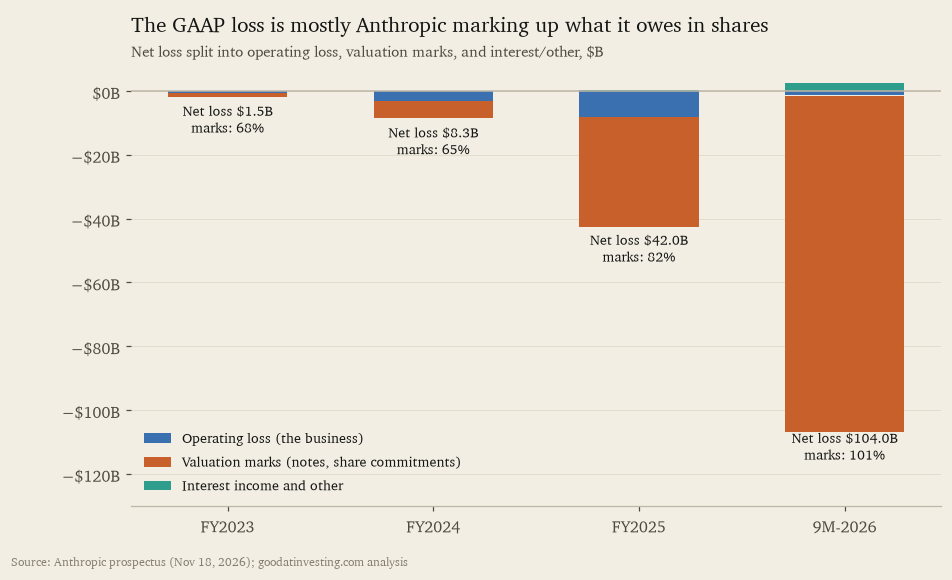

In [2]:
P = ['FY2023', 'FY2024', 'FY2025', '9M-2026']
marks = I.loc['Change in fair value of convertible notes, derivative liabilities, and SAFEs', P] \
      + oie.loc['Recognition and change in fair value of partner financing arrangements', P]
op = I.loc['Operating loss', P]
rest = I.loc['Net loss', P] - op - marks
assert np.allclose(op + marks + rest, I.loc['Net loss', P])
loss = pd.DataFrame({'operating': op, 'marks': marks, 'interest_other': rest, 'net_loss': I.loc['Net loss', P]})
loss['marks_pct_of_loss'] = loss.marks / loss.net_loss * 100
print((loss / B).round(1).assign(marks_pct_of_loss=loss.marks_pct_of_loss.round(0)).to_string())

fig, ax = plt.subplots(figsize=(9.5, 5.2))
x = np.arange(len(P))
w = 0.58
ax.bar(x, op / B, w, color=SERIES[0], label='Operating loss (the business)')
ax.bar(x, marks / B, w, bottom=op / B - 0.15, color=SERIES[1], label='Valuation marks (notes, share commitments)')
ax.bar(x, rest.clip(lower=0) / B, w, color=SERIES[2], label='Interest income and other')
ax.axhline(0, color=AXIS, lw=1)
for i, p in enumerate(P):
    ax.text(i, loss.net_loss[p] / B - 2, f'Net loss ${-loss.net_loss[p]/B:,.1f}B\nmarks: {loss.marks_pct_of_loss[p]:.0f}%',
            ha='center', va='top', fontsize=9, color=INK)
ax.set_xticks(x, ['FY2023', 'FY2024', 'FY2025', '9M-2026'])
ax.set_ylim(loss.net_loss.min() / B * 1.25, 8)
ax.yaxis.set_major_formatter(lambda v, _: f'${v:,.0f}B' if v >= 0 else f'−${-v:,.0f}B')
ax.legend(loc='lower left', fontsize=9)
ax.set_title('The GAAP loss is mostly Anthropic marking up what it owes in shares')
subtitle(ax, 'Net loss split into operating loss, valuation marks, and interest/other, $B')
source(fig)
save(fig, '04_net_loss_history.png')
plt.show()

**What this shows** (`04_net_loss_history.png`): marks were 68% of the loss in FY2023, then 65%, 82% and **101%** of it. As the business improved and the valuation soared, the marks took over. In 9M-2026 the business (−$1.3B) plus interest (+$2.4B) was slightly *profitable*, and the marks alone made it a $104B loss.

Why the marks aren't a business cost, in one line each:
- **Amazon notes (−$94.3B):** Amazon lent $6.2B that converts into a fixed 1.84B shares. As Anthropic's value rose, those shares became worth $130.5B, and the accounting books the gap as a loss. No cash leaves, and nothing about serving customers changed. What changed is that Amazon owns a bigger slice.
- **Partner share commitments (−$11.0B):** Google and Amazon locked in a right to buy Series G-2 at $259.14 (pre-split) in March/April. The price was below fair value by the time they bought, so the discount is booked as a loss. Again: a slice of the company moved to them.
- **After the IPO** the notes convert (up to Amazon's 12% ownership cap) and the commitments are settled, so these lines mostly go away. There'll be one more mark in Q4-2026 at the IPO price.

The honest translation for investors: **the GAAP loss is the accounting shadow of dilution**. The right place to account for it is the share count, so that's where the rest of this notebook goes.

**Next:** so how many shares are there?

## 2. How many shares really exist?
**Why ask:** the income statement reports −$50 of loss per share, using 2.1B weighted-average common shares. But most of Anthropic's owners hold preferred stock, notes or awards that turn into common at the IPO. Any per-share number (EPS, value per share, the IPO price itself) only makes sense against the full count.

**Method:** add up, at Sep 30, 2026, every share that exists or is already contractually promised. All counts are post-split.
- Common outstanding (Class A + Class N), and the 846.8M Class N shares already given to the **Anthropic Public Benefit Fund** (legally outstanding, though excluded from the accounting count while a subsidiary holds them).
- **Preferred stock**, which converts 1-for-10 at the IPO.
- **Amazon's notes:** 1.84B Class N shares at the fixed conversion prices ($2.09 and $5.05).
- **Options and RSUs** already granted to employees. Options are counted in full; their $2.91 average exercise price would return ~$5B of cash, which is immaterial next to a ~$1T company.
- **Vested donation-matching and acquisition-holdback obligations.**

Shown separately and not counted: shares *reserved* but not granted (the donation-matching reserve and the equity plan pool). Those turn up in §3 as future dilution.

**Cross-check against the final prospectus (Nov 18).** Its capitalization table counts ~16.9B shares before the IPO's new ones, ~0.5B more than ours. Almost all of the gap is a line we leave in the reserve: a **"Vested Matching Obligation" of 553M Class N shares**, the most the company could owe in matches on donations employees have *pledged* against equity that has already vested. We keep it out of the count because 03/06/08 charge share-paid donations as a cost (3% of revenue), which is where those matches land as they're paid; counting the shares here too would charge them twice. Read the other way: if you count the 553M now and drop nothing else, today's count is ~3.4% higher and every per-share value ~3% lower (~$67 average instead of ~$69). Smaller items in the prospectus's count net to about zero: RSUs granted after Sep 30 (+47M) and options on the treasury-stock method (−62M).

In [3]:
s = '2026-09-30'
res = sc('common_reserved_as_converted', s)
ad = sc('antidilutive_excluded', '9M-2026')
notes = load('convertible_notes_outstanding')
opts = ad['Stock options']
stack = pd.Series({
    'Common stock outstanding': kpi('class_a_shares_outstanding') + kpi('class_n_shares_outstanding'),
    'Preferred stock (converts at IPO)': res[res.index.str.startswith('Series')].sum(),
    'Amazon convertible notes': notes['Class N Shares Issuable on Conversion'].sum() / 1e3,
    'Public Benefit Fund (issued Jun-2026)': kpi('public_benefit_fund_shares'),
    'Employee options': opts,
    'Employee RSUs': res['Stock options and restricted stock units outstanding'] - opts,
    'Donation & holdback obligations': ad['Donation matching program liability'] + ad['Holdback liability'],
})
reserved = pd.Series({
    'Donation-matching reserve': res['Shares available under Donation Matching Plan'],
    'Equity plan pool (ungranted)': res['Shares available for future issuance'],
})
fd = stack.sum()
weighted = I.loc['Weighted-average shares outstanding, basic and diluted', '9M-2026']
print((stack / B).round(2).to_string())
print(f'Fully diluted (issued or promised): {fd/1e6:.2f}B shares; + reserves {reserved.sum()/1e6:.2f}B = {(fd+reserved.sum())/1e6:.2f}B')
print(f'EPS denominator (9M-2026 weighted average): {weighted/1e6:.2f}B = {weighted/fd:.0%} of the fully diluted count')
print(f"Public Benefit Fund check: {kpi('public_benefit_fund_shares')/fd:.1%} of today's count (5% of the June count by the S-1)")

# Reference price: Sep-30 fair value of Amazon's notes / their conversion shares (same as 02 §2)
bs = wide(load('balance_sheet'))
P0 = bs.loc['Convertible notes payable', s] * 1e6 / notes['Class N Shares Issuable on Conversion'].sum()
cap0 = P0 * fd * 1e3 / 1e9
print(f'Sep-30 mark ${P0:,.2f}/share x {fd/1e6:.2f}B shares = ${cap0:,.0f}B equity value')
print(f"Net loss per share on the full count: ${I.loc['Net loss','9M-2026']*1e3/fd:,.2f} vs reported ${I.loc['Net loss per share attributable to common stockholders, basic and diluted','9M-2026']:,.0f}")

Common stock outstanding                 2199.43
Preferred stock (converts at IPO)        8558.87
Amazon convertible notes                 1840.44
Public Benefit Fund (issued Jun-2026)     846.84
Employee options                         1774.34
Employee RSUs                            1127.99
Donation & holdback obligations            29.58
Fully diluted (issued or promised): 16.38B shares; + reserves 1.44B = 17.81B
EPS denominator (9M-2026 weighted average): 2.08B = 13% of the fully diluted count
Public Benefit Fund check: 5.2% of today's count (5% of the June count by the S-1)
Sep-30 mark $70.91/share x 16.38B shares = $1,161B equity value
Net loss per share on the full count: $-6.35 vs reported $-50


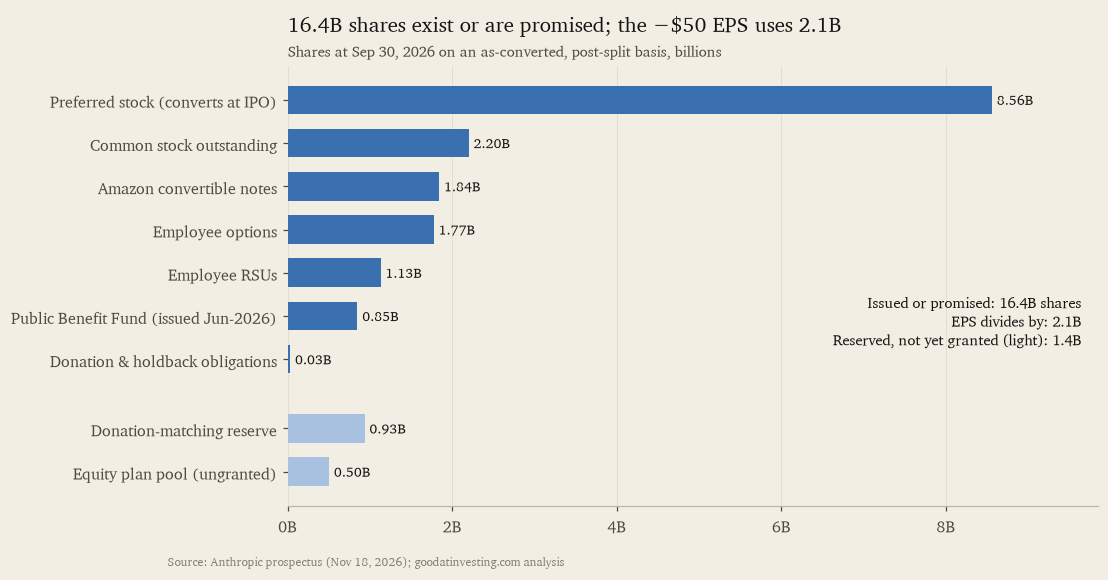

In [4]:
fig, ax = plt.subplots(figsize=(9.5, 5.2))
order = list(stack.sort_values(ascending=False).index) + list(reserved.index)
vals = pd.concat([stack, reserved])[order] / 1e6
ypos = np.r_[np.arange(len(stack)), np.arange(len(stack), len(order)) + 0.6]
ax.barh(ypos, vals, color=[SERIES[0]] * len(stack) + [LIGHT] * len(reserved), height=0.66)
for yy, v in zip(ypos, vals):
    ax.text(v + 0.06, yy, f'{v:,.2f}B', va='center', fontsize=9, color=INK)
ax.set_yticks(ypos, order)
ax.invert_yaxis()
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:,.0f}B')
ax.set_xlim(0, vals.max() * 1.15)
ax.text(0.98, 0.42, f'Issued or promised: {fd/1e6:.1f}B shares\nEPS divides by: {weighted/1e6:.1f}B\nReserved, not yet granted (light): {reserved.sum()/1e6:.1f}B',
        transform=ax.transAxes, ha='right', va='center', fontsize=10, color=INK)
ax.set_title(f'{fd/1e6:.1f}B shares exist or are promised; the −$50 EPS uses {weighted/1e6:.1f}B')
subtitle(ax, 'Shares at Sep 30, 2026 on an as-converted, post-split basis, billions')
source(fig)
save(fig, '04_share_count.png')
plt.show()

**What this shows** (`04_share_count.png`): about **16.4B** shares exist or are promised, ~8x the 2.1B the EPS uses. Preferred stock is half the count. The two items that came out of the GAAP-loss marks, Amazon's notes (1.84B) and the Public Benefit Fund (0.85B), are together about 16%. Another 1.4B sit in reserves that can be issued without new approval.

On the full count, the 9M-2026 loss is ~$6 per share rather than $50, and the *operating* loss is under 10¢. Equity value at the Sep-30 mark ($70.91/share) is about **$1.16T**. When the IPO is priced, the market cap that matters is IPO price × ~16.4B (plus IPO shares), not × the Class A float.

Two notes for the post:
- **Who holds the notes' shares matters.** Amazon converts only up to 12% of the company unless it waives the cap; the rest stays as zero-interest "rollover notes" that convert each quarter. Same shares, just later. The conversion price is the lower of the fixed price, the IPO price and (afterwards) the 10-day average price, so the share count can only go *up* if the stock falls below ~$5.
- **The Public Benefit Fund shares can be sold.** The S-1 says they "may be transferred or donated to a third party, or otherwise sold in a registered public offering". That's a 0.85B-share supply overhang, controlled by the board.

**Next:** what comes on top of today's count after the IPO?

## 3. How many new shares could come after the IPO?
**Why ask:** today's count is already in the price an IPO buyer pays. What hurts is *new* shares issued later without new money coming in, and the S-1 builds several of those into the structure.

**Sources, and how we size each through 2030:**

| Source | What the S-1 says | How we size it |
|---|---|---|
| New employee grants | $34.1B of granted-but-unexpensed awards are already in §2. The 2026 Plan reserve tops up by up to 5% a year (ESPP by 1%) | 03's projected stock comp minus the already-granted backlog, ÷ share price |
| Share-paid donations | Company matches employee pledges in Class N shares; $2.1B in 9M-2026, and "we expect ... to increase" | 03's projected donations ÷ share price. They draw on the 0.93B reserve |
| Public Benefit Issuances | Up to 2% of all shares each time the price rises 50% above the last milestone, starting at the IPO price, at the board's discretion | 2% per 50% step in our assumed price, compounding |
| Funding the compute bill | 03's bear case runs out of cash in 2030 | Cash shortfall below the $5B minimum-liquidity covenant ÷ share price |
| Partner facilities | Google $20B, Amazon $15B, AMD $5B (all at the 30-day average price), Broadcom $42B (at 90% of it, 9% interest paid in shares) | Shown separately: they bring cash, at roughly market price |

**Share price assumption:** each scenario's price moves with its revenue, starting from the $70.91 Sep-30 mark at the clean Q3 run-rate (a constant price-to-sales multiple, ~18x). That's the one assumption that ties the dollar amounts (grants, donations, funding) to share counts, and it also sets the public-benefit milestones. A higher price means fewer shares per dollar but more public-benefit steps.

In [5]:
proj = load('projections').pivot_table(index=['scenario', 'period'], columns='metric', values='value', sort=False)
YRS = ['Q4-2026', '2027', '2028', '2029', '2030']
real = load('real_earnings')
rev0 = real[(real.metric == 'clean_revenue') & (real.period == 'Q3-2026')].value.iloc[0] * 4
backlog = kpi('rsu_unrecognized_sbc') + kpi('option_unrecognized_sbc')    # already counted in §2
pb_pct, pb_step = kpi('public_benefit_issuance_pct') / 100, kpi('public_benefit_price_step_pct') / 100
min_liquidity = 5000  # $M, A&R credit facility covenant from Q4-2026

rows = []
for sc_name in ['Bear', 'Base', 'Bull']:
    d = proj.loc[sc_name].reindex(YRS)
    ann_rev = d.revenue * np.where(d.index == 'Q4-2026', 4, 1)
    price = P0 * ann_rev / rev0                                  # constant price/sales from the Sep-30 mark
    new_sbc = (d.sbc.cumsum() - backlog).clip(lower=0).diff().fillna((d.sbc.cumsum() - backlog).clip(lower=0))
    shares = pd.DataFrame({
        'New employee grants': new_sbc * 1e3 / price,                 # $M / $ -> thousand shares
        'Share-paid donations': d.donations * 1e3 / price,
        'Funding the compute bill': (min_liquidity - d.cash_end).clip(lower=0).diff().fillna((min_liquidity - d.cash_end).clip(lower=0)).clip(lower=0) * 1e3 / price,
    })
    steps = np.floor(np.log(price.max() / P0) / np.log(1 + pb_step)) if price.max() > P0 else 0
    base_count = fd + shares.sum().sum()
    pb = base_count * ((1 + pb_pct) ** steps - 1)
    tot = shares.sum()
    tot['Public Benefit Issuances'] = pb
    for k, v in tot.items():
        rows.append(dict(scenario=sc_name, source=k, shares_k=v, pct_of_fd=v / fd * 100))
    print(f'{sc_name}: 2030 price ${price.iloc[-1]:,.0f} ({price.iloc[-1]/P0:.1f}x the mark), {int(steps)} public-benefit steps, '
          f'new shares {tot.sum()/1e6:.2f}B = +{tot.sum()/fd:.1%}')

fut = pd.DataFrame(rows)
print(fut.pivot_table(index='source', columns='scenario', values='pct_of_fd', sort=False).round(1).to_string())

fac = load('note_facilities_2026')
facilities = fac['Aggregate Amount Available for Issuance (in millions)'].sum() + kpi('amd_share_purchase_commitment')
print(f'Partner facilities: ${facilities/B:,.0f}B; settled in shares at the Sep-30 mark = {facilities*1e3/P0/1e6:.2f}B shares '
      f'(+{facilities*1e3/P0/fd:.1%}); Broadcom at 90% of the price adds a {1-kpi("broadcom_npa_conversion_pct_of_vwap")/100:.0%} discount on $42B')
print(f'Bear funding gap at a flat ${P0:.0f} price instead: '
      f'{(min_liquidity - proj.loc["Bear"].cash_end.min())*1e3/P0/fd:+.1%} of shares')

Bear: 2030 price $118 (1.7x the mark), 1 public-benefit steps, new shares 0.92B = +5.6%
Base: 2030 price $290 (4.1x the mark), 3 public-benefit steps, new shares 1.26B = +7.7%
Bull: 2030 price $830 (11.7x the mark), 6 public-benefit steps, new shares 2.33B = +14.2%
scenario                  Bear  Base  Bull
source                                    
New employee grants        0.9   0.8   0.7
Share-paid donations       0.7   0.7   0.7
Funding the compute bill   2.0   0.0   0.0
Public Benefit Issuances   2.1   6.2  12.8
Partner facilities: $82B; settled in shares at the Sep-30 mark = 1.16B shares (+7.1%); Broadcom at 90% of the price adds a 10% discount on $42B
Bear funding gap at a flat $71 price instead: +3.3% of shares


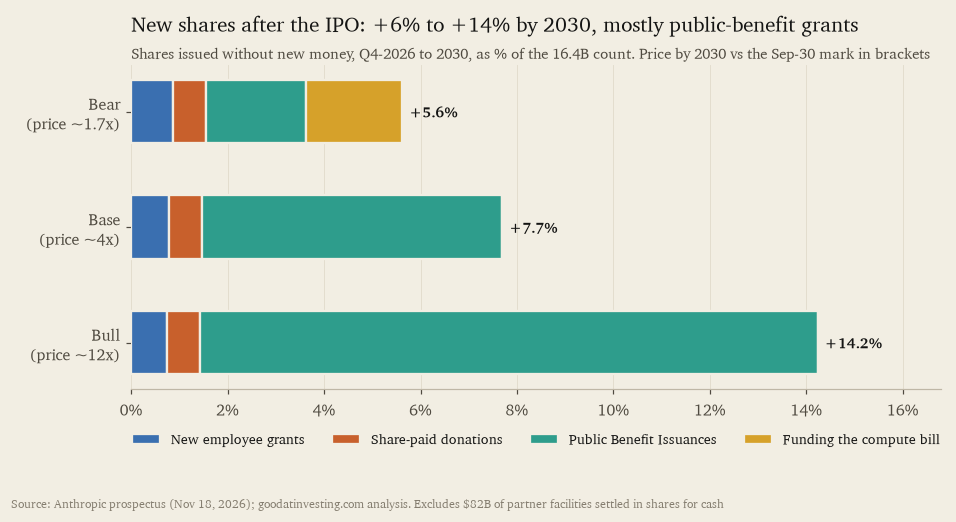

In [6]:
srcs = ['New employee grants', 'Share-paid donations', 'Public Benefit Issuances', 'Funding the compute bill']
tab = fut.pivot_table(index='scenario', columns='source', values='pct_of_fd').reindex(['Bull', 'Base', 'Bear'])[srcs]
fig, ax = plt.subplots(figsize=(9.5, 4.6))
y = np.arange(len(tab))
left = np.zeros(len(tab))
for c, col in zip(SERIES, srcs):
    ax.barh(y, tab[col], left=left, color=c, height=0.55, label=col, edgecolor=SURFACE, linewidth=1.5)
    left += tab[col].values
for yy, t in zip(y, left):
    ax.text(t + 0.15, yy, f'+{t:.1f}%', va='center', fontsize=10, color=INK, fontweight='bold')
ax.set_yticks(y, [f'{s}\n(price {p})' for s, p in zip(tab.index, ['~12x', '~4x', '~1.7x'])])
ax.grid(axis='y', visible=False); ax.grid(axis='x', visible=True)
ax.xaxis.set_major_formatter(lambda v, _: f'{v:.0f}%')
ax.set_xlim(0, left.max() * 1.18)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.09), ncol=4, fontsize=9)
fig.subplots_adjust(bottom=0.24)
ax.set_title('New shares after the IPO: +6% to +14% by 2030, mostly public-benefit grants')
subtitle(ax, 'Shares issued without new money, Q4-2026 to 2030, as % of the 16.4B count. Price by 2030 vs the Sep-30 mark in brackets')
source(fig, 'Source: Anthropic prospectus (Nov 18, 2026); goodatinvesting.com analysis. Excludes $82B of partner facilities settled in shares for cash')
save(fig, '04_future_dilution.png')
plt.show()

**What this shows** (`04_future_dilution.png`). Check the printed numbers above before quoting; the ranges here are rounded.
- **Bull (+14%):** the price rises ~12x, which clears six 50% milestones. At 2% each, the Public Benefit Fund gets ~13% more shares. *Shareholders' slice shrinks most exactly when they're doing best.* That's deliberate: the S-1 says the public benefit should "share meaningfully in that growth".
- **Base (+8%):** price ~4x, three milestones (~6%), plus ~1.5% from new grants and donations.
- **Bear (+6%):** one milestone (2%), grants and donations (~1.5%), and ~2% of new equity to fund the 2030 cash gap. That last piece assumes the price still rises 1.7x; at a flat $71 it's 3.3%, and a falling price makes it worse. The gap keeps growing after 2030.
- **New grants and donations are small in shares (~1.5% in every case)** because the price is assumed to rise with revenue, so each dollar of stock comp buys fewer shares. Their cost is already in our real operating income.

**Partner facilities** sit outside the chart because they bring cash: Google, Amazon and AMD buy shares at about the market price, and Broadcom's notes convert at a 10% discount (15% if revenue conditions slip) with 9% interest paid in more notes. Fully drawn, that's ~$82B, about 7% of today's count at the Sep-30 mark. These shares pay for compute, so they're dilution with something in return, but they also hand ownership to Anthropic's suppliers.

Not sized, but worth a line in the post:
- **The IPO itself** (primary shares, and Google's option to buy up to $10B at the IPO price). Blank in this amendment.
- **Founders' 80% pledge** to philanthropy. Not new shares, but future selling or donation of a large block.
- **Lock-up expiry** and the Public Benefit Fund's ability to sell: supply, not dilution.

**Next:** does any of this change the business?

## 4. Which of this touches the business?
**Why ask:** the user-facing claim of this post is "the GAAP loss isn't the business". Be precise about where that holds.

| Item | Changes revenue, margins or cash? | Changes your share of them? |
|---|---|---|
| Note / share-commitment marks (the GAAP loss) | **No.** Non-cash, and they end at the IPO | Yes, through §2's 1.84B note shares and the partners' G-2 stock |
| Preferred conversion, options, RSUs already granted | No (option exercise brings in ~$5B) | Already in the 16.4B; price the IPO against it |
| New employee grants | Yes: stock comp is a real cost, already in "real" operating income (02) | Yes, ~1% through 2030 at rising prices; more if the price stalls |
| Share-paid donations | Yes: a real cost in "real" operating income, 12% of Q3 revenue | Yes |
| Public Benefit Issuances | **No P&L charge expected while the Fund is a subsidiary**, so they won't show up in any earnings number | Yes, up to 2% per 50% price rise. The most invisible dilution in the filing |
| Partner facilities | Brings cash for compute; Broadcom notes carry 9% interest in kind | Yes, at roughly market price |
| Bear-case equity raise | Funds the compute commitments | Yes |

So: **the GAAP loss doesn't touch the business, and neither do most of the share-count items.** They all land on the per-share line instead. The two that touch both (stock comp and donations) are already charged in our real operating income and owner FCF. The one to watch is the Public Benefit framework: it dilutes without ever hitting reported earnings, so per-share metrics are the only place to see it.

In [7]:
out = pd.concat([
    pd.DataFrame({'scenario': 'today', 'source': stack.index, 'shares_k': stack.values, 'pct_of_fd': stack.values / fd * 100}),
    pd.DataFrame({'scenario': 'today_reserved', 'source': reserved.index, 'shares_k': reserved.values, 'pct_of_fd': reserved.values / fd * 100}),
    fut,
])
out['as_of'] = '2026-09-30'
out.to_csv(DATA / 'dilution.csv', index=False)
print(f'dilution.csv: {len(out)} rows')

dilution.csv: 21 rows


## Findings, by section
1. Valuation marks were most of the GAAP net loss in every period, rising to 101% in 9M-2026. The business plus interest income was slightly profitable before them (`04_net_loss_history.png`).
2. ~16.4B shares exist or are promised at Sep 30, 2026, vs 2.1B in the EPS denominator. The marks' economic legacy is ~2.7B of those (Amazon notes 1.84B, Public Benefit Fund 0.85B). Equity value at the Sep-30 mark is ~$1.16T (`04_share_count.png`).
3. New shares without new money through 2030: +6% (bear), +8% (base), +14% (bull) of today's count. Public-benefit steps are most of it, making dilution *highest* in the bull case. Partner facilities could add ~7% more, for cash (`04_future_dilution.png`).
4. None of it changes the operating business. Stock comp and donations are already costs in our "real" numbers; Public Benefit Issuances never hit earnings at all.

## Caveats
- **Share price path is assumed** (constant price/sales from the Sep-30 mark). It drives both the public-benefit steps and the dollar-to-share conversion. A lower multiple makes dollar-based dilution larger and public-benefit dilution smaller.
- The Sep-30 mark ($70.91) stands in for the IPO price, which is blank; public-benefit milestones start from the actual IPO price.
- Public Benefit Issuances are "up to" 2% and at the board's discretion; we assume the maximum at every milestone. Milestones also need the price to hold above the threshold for 90 of 120 trading days.
- Options counted gross (no treasury-stock method); the difference is under 0.5% of the count.
- The fully diluted count here differs slightly from the S-1's June-30 basis for the Public Benefit Fund (5.2% vs 5%).

## Open items
- Re-run on the priced amendment: IPO shares, the pro forma share table (blank today), the note shares that actually convert under Amazon's cap, and whether Google takes its $10B at the IPO price.
- A valuation notebook (05) can now divide by the right share count.